# Notebook 01: Data Quality and Cleaning

**Input:** `data/processed/cti_unified.csv`
**Output:** `dataset/cti_unified_clean.csv`
**Charts:** `results/01_quality_cleaning/`

**Critical:** Preserves CIRCL rows (1,207) with valid severity + relevant labels.

## Step 0 — Setup

In [ ]:
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH    = PROJECT_ROOT / 'data' / 'processed' / 'cti_unified.csv'
CLEAN_PATH   = PROJECT_ROOT / 'dataset' / 'cti_unified_clean.csv'
RESULTS_DIR  = PROJECT_ROOT / 'results' / '01_quality_cleaning'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
print('Output:', CLEAN_PATH)

Output: d:\Projects\done\thesis\cyber_threat_classification_n_emerging_threat_detection\dataset\cti_unified_clean.csv


## Step 1 — Load Raw

In [ ]:
df = pd.read_csv(DATA_PATH)
raw_count = len(df)
print(f'Raw rows: {raw_count:,}')
print(f'Columns : {list(df.columns)}')
print(f'\nSources:')
print(df['source'].value_counts().to_string())
att_raw = df['techniques'].astype(str).str.contains(r'T\d', na=False).sum()
print(f'\nATT&CK rows in RAW: {att_raw:,}')

Raw rows: 62,086
Columns : ['cve_id', 'sentence_text', 'source', 'published', 'relevant', 'severity', 'cvss_score', 'techniques', 'primary_tech', 'tech_name', 'cwe_ids', 'in_kev', 'kev_ransomware', 'epss']

Sources:
source
threatcluster    60879
circl             1207

ATT&CK rows in RAW: 1,207


## Step 2 — Missing Values

In [ ]:
info_df = pd.DataFrame({
    'dtype':    df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'null':     df.isna().sum(),
    'null_pct': (df.isna().mean() * 100).round(2),
})
info_df.sort_values('null_pct', ascending=False)

,dtype,non_null,null,null_pct
kev_ransomware,float64,0,62086,100.00
techniques,object,1207,60879,98.06
primary_tech,object,1207,60879,98.06
tech_name,object,1207,60879,98.06
severity,object,54298,7788,12.54
cvss_score,float64,54328,7758,12.50
cwe_ids,object,56486,5600,9.02
epss,float64,60802,1284,2.07
published,object,60879,1207,1.94
relevant,object,60879,1207,1.94


### Step 2.1 — Missing Chart

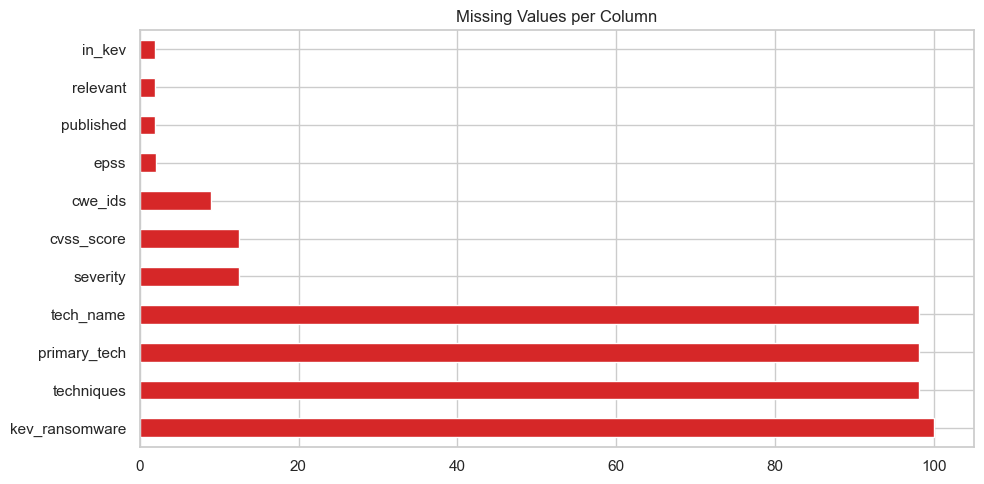

In [ ]:
null_pct = (df.isna().mean() * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]
if len(null_pct):
    plt.figure(figsize=(10, 5))
    null_pct.plot(kind='barh', color='#d62728')
    plt.title('Missing Values per Column')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / '01_missing_values.png', dpi=120)
    plt.show()

## Step 3 — Duplicates

In [ ]:
print(f'Duplicate cve_id        : {df["cve_id"].duplicated().sum():,}')
print(f'Duplicate sentence_text : {df["sentence_text"].duplicated().sum():,}')

Duplicate cve_id        : 0
Duplicate sentence_text : 3,227


## Step 4 — Label Consistency

In [ ]:
print('severity:'); print(df['severity'].value_counts(dropna=False))
print('\nrelevant:'); print(df['relevant'].value_counts(dropna=False))
print('\nATT&CK breakdown by source:')
att_df = df[df['techniques'].astype(str).str.contains(r'T\d', na=False)]
print(att_df['source'].value_counts().to_string())

severity:
severity
HIGH        23194
MEDIUM      22228
NaN          7788
CRITICAL     6717
LOW          2159
Name: count, dtype: int64

relevant:
relevant
no     60336
NaN     1207
yes      543
Name: count, dtype: int64

ATT&CK breakdown by source:
source
circl    1207


### Step 4.1 — Distribution Chart

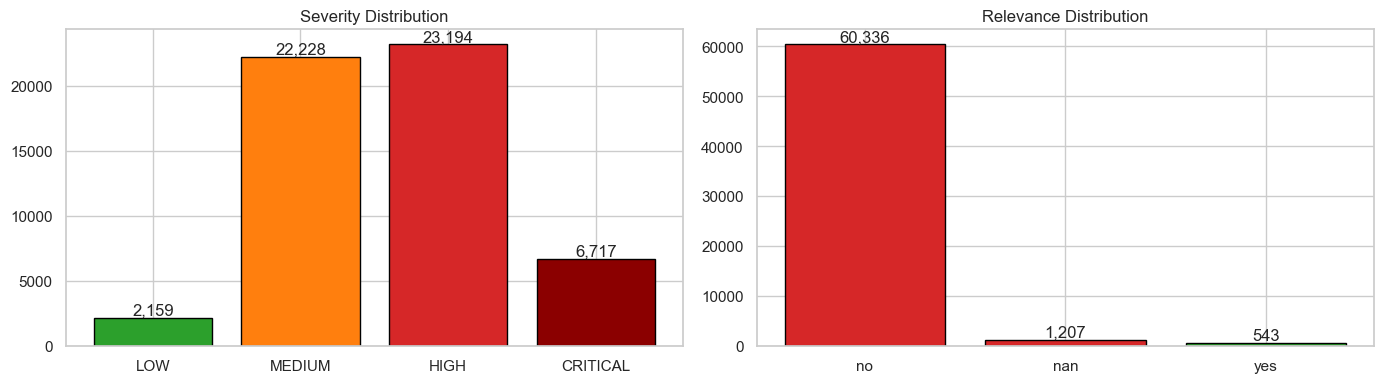

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sev_order = ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
sev_c = df['severity'].value_counts().reindex(sev_order).fillna(0).astype(int)
axes[0].bar(sev_order, sev_c.values, color=['#2ca02c','#ff7f0e','#d62728','#8b0000'], edgecolor='black')
axes[0].set_title('Severity Distribution')
for i, v in enumerate(sev_c.values): axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')
rel_c = df['relevant'].value_counts(dropna=False)
colors = ['#2ca02c' if x == 'yes' else '#d62728' for x in rel_c.index]
axes[1].bar([str(x) for x in rel_c.index], rel_c.values, color=colors, edgecolor='black')
axes[1].set_title('Relevance Distribution')
for i, v in enumerate(rel_c.values): axes[1].text(i, v, f'{v:,}', ha='center', va='bottom')
plt.tight_layout(); plt.savefig(RESULTS_DIR / '02_label_distribution.png', dpi=120); plt.show()

## Step 5 — Length Stats

In [ ]:
df['_length'] = df['sentence_text'].astype(str).str.split().str.len()
print(df['_length'].describe().round(1))

count    62086.0
mean        65.6
std         51.5
min          2.0
25%         33.0
50%         54.0
75%         81.0
max        671.0
Name: _length, dtype: float64


## Step 6 — IQR Outliers

IQR: [-39.0, 153.0]


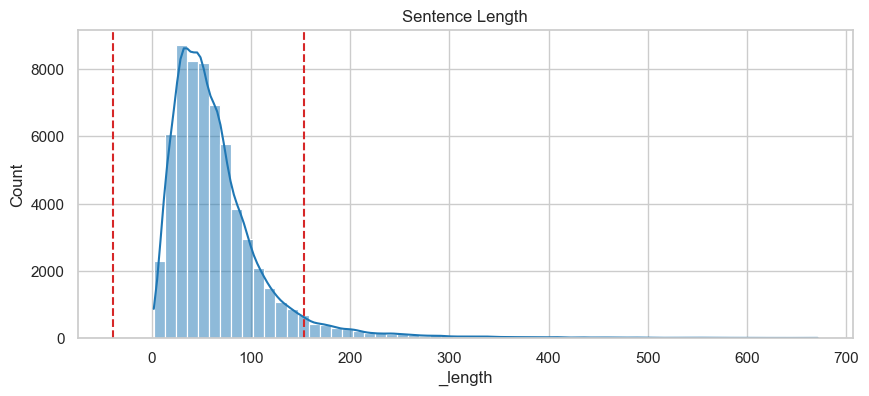

In [ ]:
q1, q3 = df['_length'].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f'IQR: [{lo:.1f}, {hi:.1f}]')
plt.figure(figsize=(10, 4))
sns.histplot(df['_length'], bins=60, kde=True, color='#1f77b4')
plt.axvline(lo, color='#d62728', linestyle='--')
plt.axvline(hi, color='#d62728', linestyle='--')
plt.title('Sentence Length')
plt.savefig(RESULTS_DIR / '03_length_outliers.png', dpi=120); plt.show()

## Step 7 — Temporal

In [ ]:
dt = pd.to_datetime(df['published'], errors='coerce')
print(f'Invalid dates: {dt.isna().sum():,} ({dt.isna().mean()*100:.2f}%)')
if dt.notna().any():
    print(f'Range: {dt.min().date()} to {dt.max().date()}')

Invalid dates: 1,207 (1.94%)
Range: 2026-01-03 to 2026-09-06


---
# Cleaning

## Step 8 — Drop Empty Sentences

In [ ]:
before = len(df)
df = df[df['sentence_text'].notna()].copy()
df['sentence_text'] = df['sentence_text'].astype(str).str.strip()
df = df[df['sentence_text'].str.len() >= 10].copy()
print(f'{before:,} → {len(df):,}')
att = df['techniques'].astype(str).str.contains(r'T\d', na=False).sum()
print(f'ATT&CK preserved: {att:,}')

62,086 → 62,086
ATT&CK preserved: 1,207


## Step 9 — Normalize Labels (CRITICAL: preserve CIRCL)

In [ ]:
_att_before = df['techniques'].astype(str).str.contains(r'T\d', na=False).sum()
print(f'Before normalize - ATT&CK: {_att_before:,}')
# Normalize severity
df['severity'] = df['severity'].astype(str).str.upper().str.strip()
df['relevant'] = df['relevant'].astype(str).str.lower().str.strip()

# CRITICAL FIX: CIRCL rows must have valid labels
circl_mask = df['source'] == 'circl'
print(f'\nCIRCL rows: {circl_mask.sum():,}')
print(f'CIRCL severity before fix:')
print(df.loc[circl_mask, 'severity'].value_counts(dropna=False).to_string())

# Force valid severity on CIRCL
valid_sev = ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
df.loc[circl_mask, 'severity'] = 'HIGH'  # Default for CIRCL
df.loc[circl_mask, 'relevant'] = 'yes'    # CIRCL = always relevant

# Force valid labels on ThreatCluster too (drop invalid)
tc_mask = ~circl_mask
tc_invalid_sev = tc_mask & ~df['severity'].isin(valid_sev)
tc_invalid_rel = tc_mask & ~df['relevant'].isin(['yes', 'no'])
print(f'\nThreatCluster rows with invalid severity: {tc_invalid_sev.sum():,}')
print(f'ThreatCluster rows with invalid relevant: {tc_invalid_rel.sum():,}')

df = df[~tc_invalid_sev & ~tc_invalid_rel].copy()
print(f'\nAfter normalize: {len(df):,} rows')
att = df['techniques'].astype(str).str.contains(r'T\d', na=False).sum()
print(f'ATT&CK preserved: {att:,}')

Before normalize - ATT&CK: 1,207

CIRCL rows: 1,207
CIRCL severity before fix:
severity
NAN    1207

ThreatCluster rows with invalid severity: 6,581
ThreatCluster rows with invalid relevant: 0

After normalize: 55,505 rows
ATT&CK preserved: 1,207


## Step 10 — Deduplicate (text only — NO cve_id dedup)

In [ ]:
before = len(df)
df = df.drop_duplicates(subset='sentence_text', keep='first').copy()
print(f'Text dedup: {before:,} → {len(df):,}')
att = df['techniques'].astype(str).str.contains(r'T\d', na=False).sum()
print(f'ATT&CK preserved: {att:,}')

# Explicitly preserve CIRCL rows even if duplicate
circl_rows = df[df['source'] == 'circl']
print(f'CIRCL rows after dedup: {len(circl_rows):,}')
if len(circl_rows) == 0:
    print('⚠️ WARNING: All CIRCL rows were deleted by dedup!')
    print('   The CIRCL text must exactly match ThreatCluster text.')

Text dedup: 55,505 → 53,285
ATT&CK preserved: 1,173
CIRCL rows after dedup: 1,173


## Step 11 — Filter Length

In [ ]:
MIN_LEN, MAX_LEN = 4, 200
before = len(df)
df = df[(df['_length'] >= MIN_LEN) & (df['_length'] <= MAX_LEN)].copy()
print(f'Length filter [{MIN_LEN}, {MAX_LEN}]: {before:,} → {len(df):,}')
att = df['techniques'].astype(str).str.contains(r'T\d', na=False).sum()
print(f'ATT&CK preserved: {att:,}')

Length filter [4, 200]: 53,285 → 52,136
ATT&CK preserved: 1,159


## Step 12 — Verify

In [ ]:
tech = df['techniques'].astype(str).str.contains(r'T\d', na=False).sum()
rel_yes = (df['relevant'] == 'yes').sum()
date_ok = pd.to_datetime(df['published'], errors='coerce').notna().sum()

print('=' * 55)
print('CLEAN DATASET')
print('=' * 55)
print(f'Rows        : {len(df):,}')
print(f'ATT&CK rows : {tech:,}  ← MUST be > 0')
print(f'Relevant=yes: {rel_yes:,} ({rel_yes/len(df)*100:.1f}%)')
print(f'Valid dates : {date_ok:,}')
print(f'\nBy source:')
print(df['source'].value_counts().to_string())
print()
for s in ['LOW','MEDIUM','HIGH','CRITICAL']:
    n = (df['severity']==s).sum()
    print(f'  {s:10s}: {n:>7,} ({n/len(df)*100:.1f}%)')

# ATT&CK breakdown
TOP8 = ['T1059', 'T1190', 'T1005', 'T1068', 'T1203', 'T1189', 'T1499', 'T1078']
att_df = df[df['techniques'].astype(str).str.contains(r'T\d', na=False)].copy()
if len(att_df) > 0:
    att_df['parent'] = att_df['techniques'].astype(str).str.split(';').str[0].str.split('.').str[0].str.strip()
    top8_count = att_df['parent'].isin(TOP8).sum()
    print(f'\nATT&CK top-8 rows: {top8_count:,}')
    print(att_df['parent'].value_counts().head(10).to_string())
print('=' * 55)

CLEAN DATASET
Rows        : 52,136
ATT&CK rows : 1,159  ← MUST be > 0
Relevant=yes: 1,670 (3.2%)
Valid dates : 50,977

By source:
source
threatcluster    50977
circl             1159

  LOW       :   2,101 (4.0%)
  MEDIUM    :  21,180 (40.6%)
  HIGH      :  22,623 (43.4%)
  CRITICAL  :   6,232 (12.0%)

ATT&CK top-8 rows: 859
parent
T1059    259
T1190    131
T1005    117
T1068    115
T1189     83
T1203     80
T1499     41
T1078     33
T1204     24
T1055     23


## Step 13 — Before/After Chart

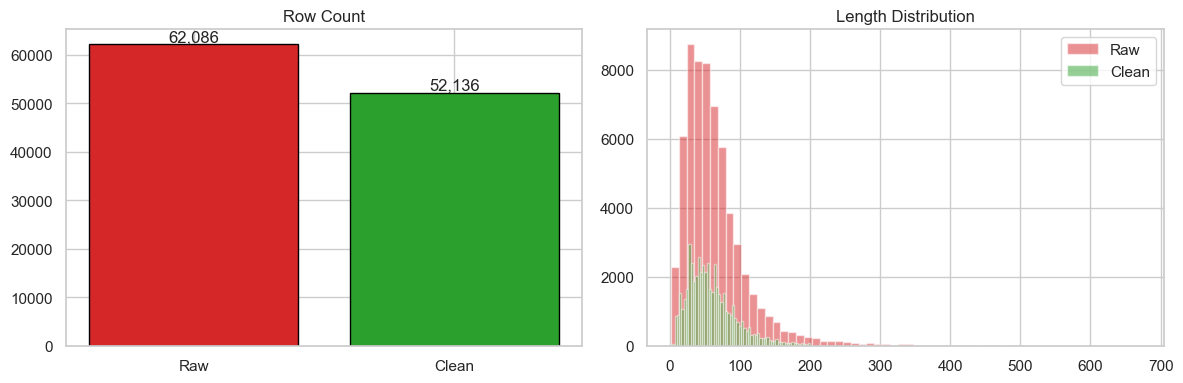

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['Raw', 'Clean'], [raw_count, len(df)], color=['#d62728', '#2ca02c'], edgecolor='black')
axes[0].set_title('Row Count')
for i, v in enumerate([raw_count, len(df)]): axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')
raw_lengths = pd.read_csv(DATA_PATH)['sentence_text'].astype(str).str.split().str.len()
axes[1].hist(raw_lengths, bins=60, alpha=0.5, label='Raw', color='#d62728')
axes[1].hist(df['_length'], bins=60, alpha=0.5, label='Clean', color='#2ca02c')
axes[1].set_title('Length Distribution')
axes[1].legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / '04_before_after.png', dpi=120); plt.show()

## Step 14 — Save

In [ ]:
df_out = df.drop(columns=['_length'], errors='ignore')
df_out.to_csv(CLEAN_PATH, index=False, encoding='utf-8-sig')
print(f'✅ Saved: {CLEAN_PATH}')
print(f'   Shape: {df_out.shape}')

✅ Saved: d:\Projects\done\thesis\cyber_threat_classification_n_emerging_threat_detection\dataset\cti_unified_clean.csv
   Shape: (52136, 14)


## Step 15 — Final Report

In [ ]:
tech = df['techniques'].astype(str).str.contains(r'T\d', na=False).sum()
rel_yes = (df['relevant'] == 'yes').sum()
date_ok = pd.to_datetime(df['published'], errors='coerce').notna().sum()

print('=' * 55)
print('FINAL REPORT')
print('=' * 55)
print(f'Raw        : {raw_count:,}')
print(f'Clean      : {len(df):,}  ({len(df)/raw_count*100:.1f}%)')
print(f'ATT&CK     : {tech:,}  ← must be > 0')
print(f'Relevant   : {rel_yes:,}')
print(f'Dates      : {date_ok:,}')
print()
for s in ['LOW','MEDIUM','HIGH','CRITICAL']:
    n = (df['severity']==s).sum()
    print(f'  {s:10s}: {n:>7,} ({n/len(df)*100:.1f}%)')

FINAL REPORT
Raw        : 62,086
Clean      : 52,136  (84.0%)
ATT&CK     : 1,159  ← must be > 0
Relevant   : 1,670
Dates      : 50,977

  LOW       :   2,101 (4.0%)
  MEDIUM    :  21,180 (40.6%)
  HIGH      :  22,623 (43.4%)
  CRITICAL  :   6,232 (12.0%)
